Specificity: Computes the Kalman filter on IV. It also does training on quotes and testing on trades. Results+evaluations plotted. 

In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)


import arbitrage
import black_scholes
import ekf
import events
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.plots as plots
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [3]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

In [4]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_quote_result, df_trade_result = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    # min_trades=100,
)

Skipping O:SPY240105C00388000: no matched trades
Skipping O:SPY240105C00424000: no matched trades
Skipping O:SPY240105C00425000: no matched trades
Skipping O:SPY240105C00441000: no matched trades
Skipping O:SPY240105C00443000: no matched trades
Skipping O:SPY240105C00453000: no matched trades
O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000

In [5]:
df_quote_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_iv,bid_price,ask_price,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.003357440 EST,0.31989,0.312129,0.326719,0.31989,0.02,0.03,0.025173,442.0,false
2024-01-03 09:30:00.006736128 EST,0.140982,0.138439,0.143359,0.140982,0.04,0.05,0.045034,481.0,true
2024-01-03 09:30:00.006781440 EST,0.13695,0.134075,0.139497,0.13695,0.09,0.11,0.100363,479.0,true
2024-01-03 09:30:00.007484160 EST,0.143359,0.132705,0.15164,0.141236,0.03,0.07,0.045551,481.0,true
2024-01-03 09:30:00.008294144 EST,0.127732,0.126371,0.129092,0.127732,2.17,2.21,2.189967,471.0,false
…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,0.145804,0.145401,0.146126,0.145803,1.88,1.89,1.88553,469.0,true
2024-01-03 16:14:59.884593152 EST,0.091882,0.07433,0.104474,0.093966,5.28,5.38,5.334368,474.0,false
2024-01-03 16:14:59.884598272 EST,0.110311,0.108205,0.114425,0.110651,3.66,3.72,3.68344,472.0,false


In [6]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.137318,-0.006573,0.103182,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.059 EST,0.153329,0.01,0.1651,0.0,0.05,null,null,NaN,483.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150646,0.003677,0.227992,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.128923,0.128139,0.128923,1.03,1.04,0.12846,0.000463,1.034098,467.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false


In [7]:
df_trade_result = df_trade_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_trade_result.shape[0]:,} rows with no nulls / NaNs out of {df_trade_result.shape[0]:,}")

74,831 rows with no nulls / NaNs out of 74,831


In [8]:
df_trade_result.select(pl.col("trade_residual") ** 2).mean() * 100000

trade_residual
f64
1.571381


## Quptes smile

In [9]:
import personal.shared_functions.utils as _u

df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [10]:
row

ts_ns,bid_iv_270_C,ask_iv_270_C,kalman_iv_270_C,bid_iv_375_C,ask_iv_375_C,kalman_iv_375_C,bid_iv_376_C,ask_iv_376_C,kalman_iv_376_C,bid_iv_378_C,ask_iv_378_C,kalman_iv_378_C,bid_iv_379_C,ask_iv_379_C,kalman_iv_379_C,bid_iv_386_C,ask_iv_386_C,kalman_iv_386_C,bid_iv_387_C,ask_iv_387_C,kalman_iv_387_C,bid_iv_397_C,ask_iv_397_C,kalman_iv_397_C,bid_iv_400_C,ask_iv_400_C,kalman_iv_400_C,bid_iv_406_C,ask_iv_406_C,kalman_iv_406_C,bid_iv_410_C,ask_iv_410_C,kalman_iv_410_C,bid_iv_421_C,ask_iv_421_C,kalman_iv_421_C,…,kalman_iv_480_P,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_P,ask_iv_481_P,kalman_iv_481_P,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_P,ask_iv_482_P,kalman_iv_482_P,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_P,ask_iv_483_P,kalman_iv_483_P,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,bid_iv_485_P,ask_iv_485_P,kalman_iv_485_P,bid_iv_490_P,ask_iv_490_P,kalman_iv_490_P,bid_iv_493_P,ask_iv_493_P,kalman_iv_493_P,bid_iv_500_P,ask_iv_500_P,kalman_iv_500_P
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 14:04:53.013474304 EST,0.01,3.714766,2.718145,0.01,1.694864,1.375521,0.01,1.682541,1.366429,0.01,1.63896,1.340135,0.01,1.625573,1.329976,0.01,1.494285,1.228198,0.01,1.502504,1.223902,0.01,1.337222,1.095877,0.01,1.287883,1.031229,0.01,1.191274,0.972656,0.01,1.127417,0.906429,0.01,0.937449,0.760465,…,0.046097,0.144515,0.148946,0.14636,0.01,0.214877,0.047364,0.148901,0.155197,0.151751,0.01,0.242006,0.056591,0.15118,0.159875,0.154571,0.01,0.254611,0.071656,0.161197,0.1704,0.162625,0.15233,0.161041,0.155063,0.01,0.279131,0.076664,0.01,0.396709,0.134363,0.01,0.441135,0.138707,0.01,0.532108,0.164384


In [11]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [12]:
# has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
# has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# for i in range(0, df_filtered.shape[0], 100):
#     row = df_filtered[i]
#     ts = row["ts_ns"][0]
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     spy_mid = df_spy.filter(pl.col("ts_ns") <= ts)["price"][-1]

#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C = k in has_C_set
#         has_P = k in has_P_set

#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"][0], row[f"ask_iv_{K_int}_C"][0]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"][0], row[f"ask_iv_{K_int}_P"][0]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (
#                     row[f"kalman_iv_{K_int}_C"][0]
#                     if k > spy_mid
#                     else row[f"kalman_iv_{K_int}_P"][0]
#                 )
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"][0]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"][0]
#         else:
#             continue

#         valid_strikes.append(k)
#         valid_ivs.append(iv)

#     if not arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected at index {i} (timestamp {ts})")


In [13]:
from concurrent.futures import ThreadPoolExecutor

from joblib import Parallel, delayed

# Single join_asof instead of a per-row filter on df_spy
sample_df = df_filtered[::10]
spy_mids = (
    sample_df.select("ts_ns")
    .join_asof(df_spy.sort("ts_ns").select("ts_ns", "price"), on="ts_ns", strategy="backward")[
        "price"
    ]
    .to_list()
)

has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# Convert to plain Python once — avoids polars row access inside threads
rows = sample_df.to_dicts()
timestamps = sample_df["ts_ns"].to_list()


def check_snapshot(i, row, ts, spy_mid, expiry, otm_strikes, has_C_set, has_P_set):
    tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
    valid_strikes, valid_ivs = [], []
    for k in otm_strikes:
        K_int = int(k)
        has_C, has_P = k in has_C_set, k in has_P_set
        if has_C and has_P:
            bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
            bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
            i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
            iv = (
                (i_bid + i_ask) / 2
                if i_bid <= i_ask
                else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
            )
        elif has_C:
            iv = row[f"kalman_iv_{K_int}_C"]
        elif has_P:
            iv = row[f"kalman_iv_{K_int}_P"]
        else:
            continue
        valid_strikes.append(k)
        valid_ivs.append(iv)
    is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
        "is_arbitrage_free"
    ]
    return i, ts, is_free


results = Parallel(n_jobs=-1, backend="loky")(
    delayed(check_snapshot)(
        i * 100, rows[i], timestamps[i], spy_mids[i], expiry, otm_strikes, has_C_set, has_P_set
    )
    for i in range(len(rows))
)

for idx, ts, is_free in results:
    if not is_free:
        print(f"Arbitrage detected at index {idx} (timestamp {ts})")

[INFO/LokyProcess-1] child process calling self.run()
[INFO/LokyProcess-2] child process calling self.run()
[INFO/LokyProcess-3] child process calling self.run()
[INFO/LokyProcess-4] child process calling self.run()
[INFO/LokyProcess-5] child process calling self.run()
[INFO/LokyProcess-6] child process calling self.run()
[INFO/LokyProcess-7] child process calling self.run()
[INFO/LokyProcess-8] child process calling self.run()
[INFO/LokyProcess-10] child process calling self.run()
[INFO/LokyProcess-9] child process calling self.run()
[INFO/LokyProcess-11] child process calling self.run()
[INFO/LokyProcess-12] child process calling self.run()


Arbitrage detected at index 10717400 (timestamp 2024-01-03 14:02:34.803776-05:00)
Arbitrage detected at index 10717500 (timestamp 2024-01-03 14:02:34.809379-05:00)
Arbitrage detected at index 10717600 (timestamp 2024-01-03 14:02:34.816836-05:00)
Arbitrage detected at index 10717700 (timestamp 2024-01-03 14:02:34.818887-05:00)
Arbitrage detected at index 10717800 (timestamp 2024-01-03 14:02:34.821708-05:00)
Arbitrage detected at index 10717900 (timestamp 2024-01-03 14:02:34.831633-05:00)
Arbitrage detected at index 10718000 (timestamp 2024-01-03 14:02:34.839385-05:00)
Arbitrage detected at index 10718100 (timestamp 2024-01-03 14:02:34.853384-05:00)
Arbitrage detected at index 10718200 (timestamp 2024-01-03 14:02:34.879004-05:00)
Arbitrage detected at index 10718300 (timestamp 2024-01-03 14:02:34.892477-05:00)
Arbitrage detected at index 10718400 (timestamp 2024-01-03 14:02:34.907407-05:00)
Arbitrage detected at index 10718500 (timestamp 2024-01-03 14:02:34.910209-05:00)
Arbitrage detect

In [14]:
# def check_snapshot(args):
#     i, row, ts, spy_mid = args
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# tasks = [(i * 100, rows[i], timestamps[i], spy_mids[i]) for i in range(len(rows))]

# with ThreadPoolExecutor() as executor:
#     for idx, ts, is_free in executor.map(check_snapshot, tasks):
#         if not is_free:
#             print(f"Arbitrage detected at index {idx} (timestamp {ts})")


In [15]:
# for i in range(1, df_filtered.shape[0]):
#     row = df_filtered[i]
#     tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
#     mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
#     if not arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (calls) at index {i} (timestamp {row['ts_ns'][0]})")
#     mid_ivs_P = [row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P]
#     if not arbitrage.check_butterfly(k=strikes_P, iv=mid_ivs_P, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (puts) at index {i} (timestamp {row['ts_ns'][0]})")

In [16]:
# with dropping quotes and min_trades = 100

# Arbitrage detected at index 32975500 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected at index 32975600 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected at index 32975700 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected at index 32975800 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected at index 32975900 (timestamp 2024-01-03 10:13:05.893470-05:00)

# Arbitrage detected (calls) at index 329755 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected (calls) at index 329756 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected (calls) at index 329757 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected (calls) at index 329758 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected (calls) at index 329759 (timestamp 2024-01-03 10:13:05.893470-05:00)
# Arbitrage detected (calls) at index 1503399 (timestamp 2024-01-03 14:20:23.701259-05:00)
# Arbitrage detected (calls) at index 1738694 (timestamp 2024-01-03 14:49:31.390834-05:00)

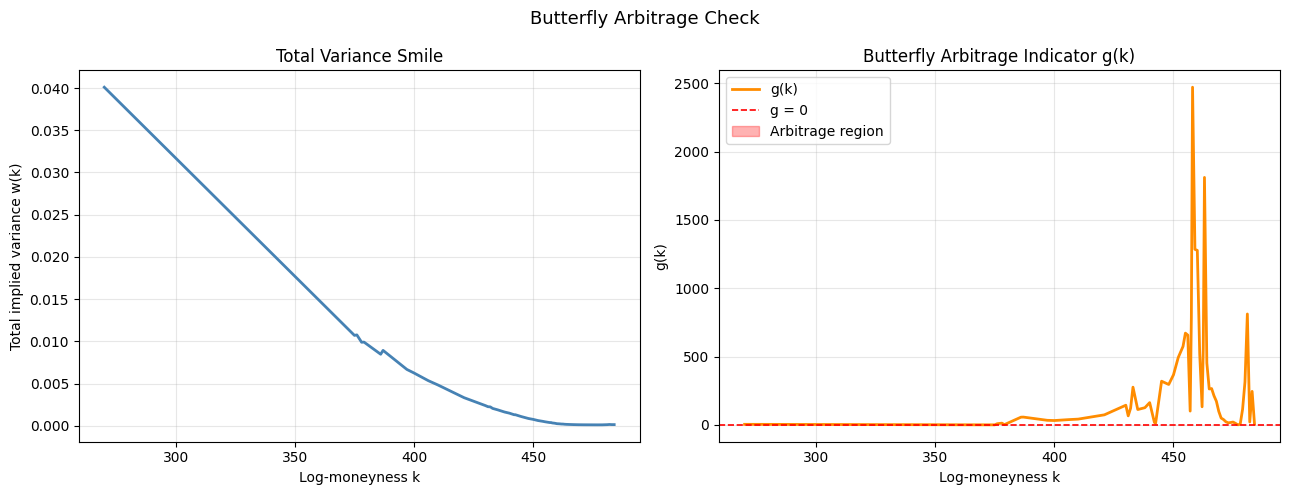

{'is_arbitrage_free': False,
 'min_g': -3.495377078346351e-05,
 'violations': array([375.]),
 'g': array([ 3.77385152e+00, -3.49537708e-05,  8.10649025e+00,  1.23984798e+01,
         1.31287386e+00,  5.61975577e+01,  5.67424800e+01,  3.32769527e+01,
         3.15647640e+01,  3.82509049e+01,  4.18960621e+01,  7.32920825e+01,
         1.43689993e+02,  6.57508710e+01,  1.21833132e+02,  2.75870186e+02,
         1.12079381e+02,  1.25528218e+02,  1.62655283e+02,  1.72049369e+01,
         1.20717639e+01,  3.19519309e+02,  2.95520046e+02,  3.66420742e+02,
         4.93293121e+02,  5.74246485e+02,  6.71575958e+02,  6.57209554e+02,
         1.00686352e+02,  7.89595793e+02,  2.47232180e+03,  1.28510904e+03,
         1.27750792e+03,  5.21623427e+02,  1.32270364e+02,  5.64029705e+02,
         1.81179210e+03,  4.52565316e+02,  2.62836210e+02,  2.65772735e+02,
         2.12534564e+02,  1.72827653e+02,  9.88724265e+01,  4.96480456e+01,
         3.86978401e+01,  2.21040571e+01,  1.46132202e+01,  1.7261

In [17]:
row = df_filtered[2192543]
tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=True)

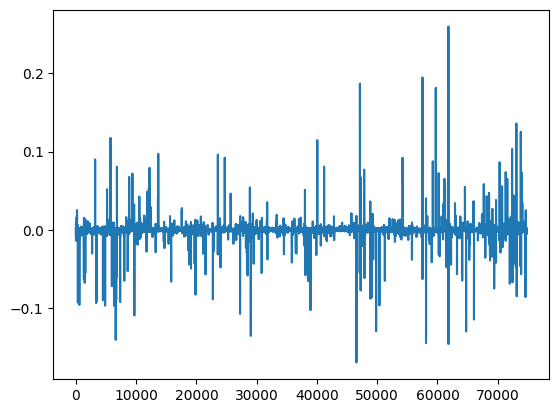

In [18]:
plt.plot(df_trade_result["trade_residual"])

In [19]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.137318,-0.006573,0.103182,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150646,0.003677,0.227992,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
2024-01-03 09:30:00.111 EST,0.145379,0.140452,0.150292,1.4,1.54,0.145914,-0.000535,1.477615,472.0,true
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.128923,0.128139,0.128923,1.03,1.04,0.12846,0.000463,1.034098,467.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false


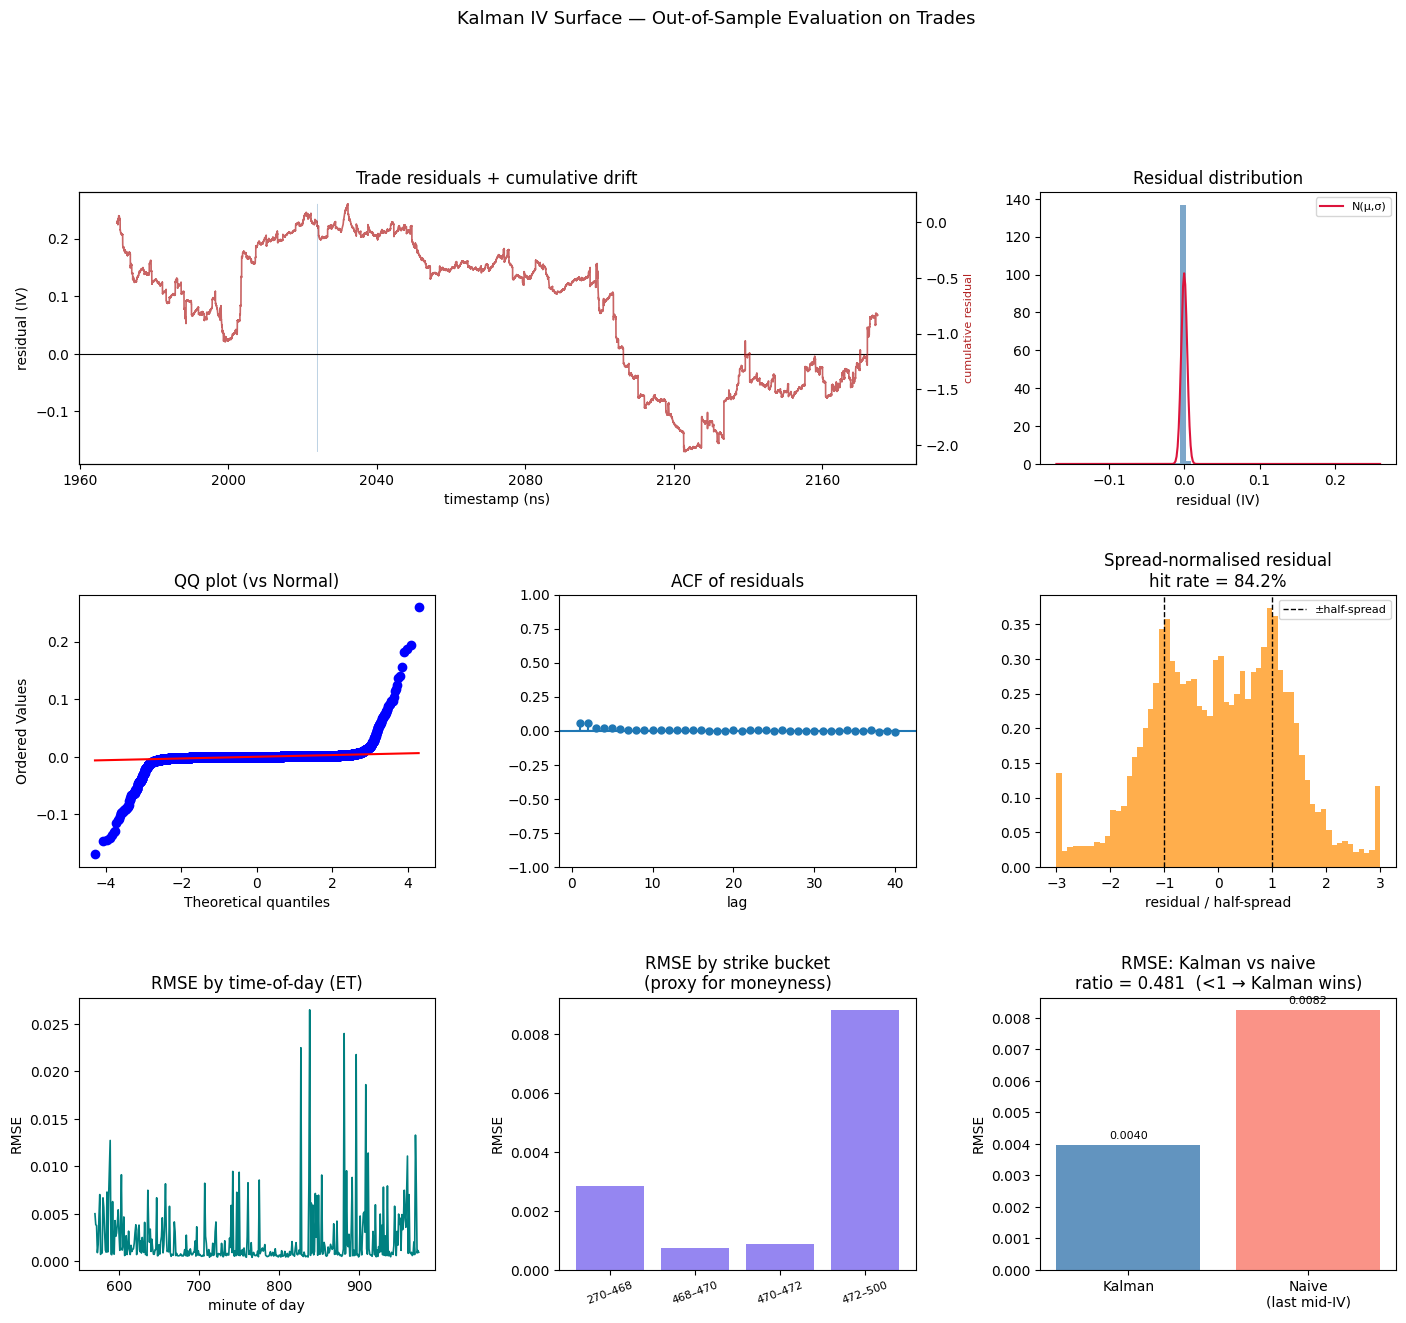

RMSE                 0.00396
MAE                  0.00080
Bias                 -0.00001
Hit rate             84.2%
Naive RMSE           0.00824
RMSE ratio           0.481  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
       lb_stat      lb_pvalue
10  594.603039  2.523659e-121
20  600.645410  2.104771e-114


In [20]:
metrics = evaluate_kalman_iv(df_quote_result, df_trade_result)

In [31]:
df_price_surface_wide = utils.synchronize_price_surface(
    df_quote_result.rename({"kalman_price": "observed_price"})
)

[INFO/LokyProcess-5] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-5] process shutting down
[INFO/LokyProcess-5] process exiting with exitcode 0
[INFO/LokyProcess-4] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-4] process shutting down
[INFO/LokyProcess-4] process exiting with exitcode 0
[INFO/LokyProcess-6] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-10] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-9] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-3] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-7] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-8] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-2] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-1] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-11] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-12] Shutting down worker after timeout 300.000s
[INFO/LokyProcess-6] proc

In [ ]:
df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_price_surface_long = df_quote_result

strikes_all = sorted(df_price_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_price_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_price_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered_price.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered_price["ts_ns"][row_idx]
row = df_price_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"observed_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"observed_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"price smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [37]:
row

ts_ns,bid_price_270_C,ask_price_270_C,observed_price_270_C,bid_price_375_C,ask_price_375_C,observed_price_375_C,bid_price_376_C,ask_price_376_C,observed_price_376_C,bid_price_378_C,ask_price_378_C,observed_price_378_C,bid_price_379_C,ask_price_379_C,observed_price_379_C,bid_price_386_C,ask_price_386_C,observed_price_386_C,bid_price_387_C,ask_price_387_C,observed_price_387_C,bid_price_397_C,ask_price_397_C,observed_price_397_C,bid_price_400_C,ask_price_400_C,observed_price_400_C,bid_price_406_C,ask_price_406_C,observed_price_406_C,bid_price_410_C,ask_price_410_C,observed_price_410_C,bid_price_421_C,ask_price_421_C,observed_price_421_C,…,observed_price_480_P,bid_price_480_C,ask_price_480_C,observed_price_480_C,bid_price_481_P,ask_price_481_P,observed_price_481_P,bid_price_481_C,ask_price_481_C,observed_price_481_C,bid_price_482_P,ask_price_482_P,observed_price_482_P,bid_price_482_C,ask_price_482_C,observed_price_482_C,bid_price_483_P,ask_price_483_P,observed_price_483_P,bid_price_483_C,ask_price_483_C,observed_price_483_C,bid_price_484_C,ask_price_484_C,observed_price_484_C,bid_price_485_P,ask_price_485_P,observed_price_485_P,bid_price_490_P,ask_price_490_P,observed_price_490_P,bid_price_493_P,ask_price_493_P,observed_price_493_P,bid_price_500_P,ask_price_500_P,observed_price_500_P
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 14:04:53.013474304 EST,199.01,200.54,199.717433,94.3,95.38,94.763972,93.29,94.46,93.83969,91.3,92.36,91.768567,90.28,91.48,90.887227,83.31,84.34,83.785431,82.31,83.46,82.84844,72.33,73.42,72.829804,69.32,70.4,69.773358,63.31,64.51,63.924,59.34,60.41,59.796921,48.3,49.47,48.91821,…,10.4703,0.05,0.06,0.054039,10.87,11.66,11.425,0.03,0.04,0.034465,11.85,12.7,12.4,0.02,0.03,0.023685,12.86,13.7,13.41,0.02,0.03,0.021435,0.02,0.03,0.022952,14.89,15.73,15.46,19.83,20.94,20.440014,22.86,23.95,23.440002,29.86,30.95,30.46


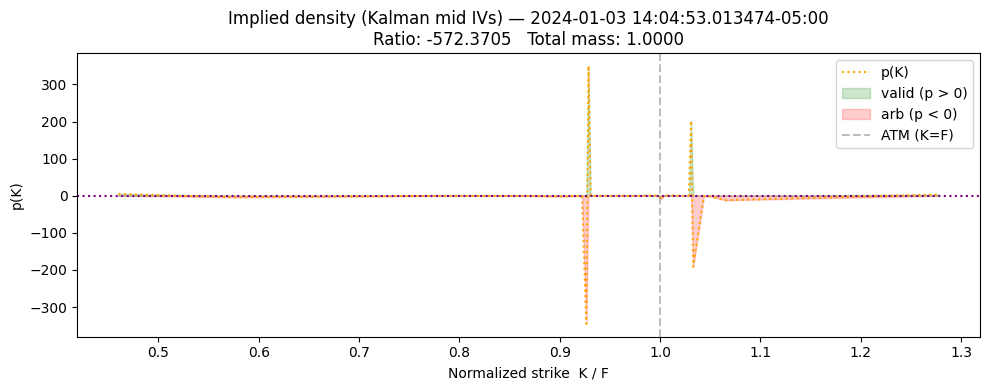

In [41]:
# ── Implied probability density from Kalman IVs (Breeden-Litzenberger) ──────
# Depends on: snapshot_ts, expiry, spy_mid, otm_strikes, otm_mid
import scipy.stats as stats


def _bs_call(F, K, T, sigma):
    """Black-Scholes call price with r=0 (forward = spot)."""
    if sigma <= 0 or T <= 0:
        return float(max(F - K, 0.0))
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return float(F * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))


F = spy_mid  # forward ≈ spot (r=0)
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

# Filter strikes with a valid Kalman mid IV
valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
strikes = np.array([v[0] for v in valid])
ivs = np.array([v[1] for v in valid])

# Normalize to pure space: kappa = K/F, C_pure = C_BS / F
pure_strikes = strikes / F
pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

# Extend strike grid with boundary conditions
strikesx = np.zeros(len(pure_strikes) + 2)
strikesx[1:-1] = pure_strikes
strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

midx = np.zeros_like(strikesx)
midx[1:-1] = pure_mids
midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
midx[-1] = 0.0  # deep OTM call → 0

# Breeden-Litzenberger: d²C/dK² = risk-neutral density
dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
p = np.diff(dCdK, append=0.0)

ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
total = np.sum(p)  # should be ≈ 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title(
    f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
)
ax.set_xlabel("Normalized strike  K / F")
ax.set_ylabel("p(K)")
ax.plot(strikesx, p, ":", color="orange", label="p(K)")
ax.fill_between(strikesx, 0, np.clip(p, 0, None), color="green", alpha=0.2, label="valid (p > 0)")
ax.fill_between(strikesx, np.clip(p, None, 0), 0, color="red", alpha=0.2, label="arb (p < 0)")
ax.axhline(0, color="purple", linestyle=":")
ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
import re


def extract_prices_from_row(row):
    pattern = re.compile(r"^(bid_price|ask_price|observed_price)_(\d+)_(C|P)$")

    calls, puts = {}, {}
    for col in row.columns:
        m = pattern.match(col)
        if not m:
            continue
        price_type, strike, cp = m.group(1), int(m.group(2)), m.group(3)
        d = calls if cp == "C" else puts
        d.setdefault(strike, {})[price_type] = row[col][0]

    strikes_C = sorted(calls)
    strikes_P = sorted(puts)

    bid_C = [calls[k].get("bid_price") for k in strikes_C]
    ask_C = [calls[k].get("ask_price") for k in strikes_C]
    observed_C = [calls[k].get("observed_price") for k in strikes_C]

    bid_P = [puts[k].get("bid_price") for k in strikes_P]
    ask_P = [puts[k].get("ask_price") for k in strikes_P]
    observed_P = [puts[k].get("observed_price") for k in strikes_P]

    return strikes_C, bid_C, ask_C, observed_C, strikes_P, bid_P, ask_P, observed_P

In [45]:
row = df_price_surface_wide[2192543]
strikes_C, bid_C, ask_C, obs_C, strikes_P, bid_P, ask_P, obs_P = extract_prices_from_row(row)

In [52]:
strikes = strikes_C
mids = obs_C
strikesx = np.zeros((len(strikes) + 2,))
strikesx[1:-1] = strikes
strikesx[0] = strikes[0] * 0.8  # strike needs to be low enough
strikesx[-1] = strikes[-1] * 1.2  # strike needs to be high enough
midx = np.zeros_like(strikesx)
midx[1:-1] = mids
midx[0] = 1.0 - strikesx[0]
midx[-1] = 0.0

dCdCK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
p = np.diff(dCdCK, append=0.0)
ratio = np.sum(p[p < 0.0])
total = np.sum(p)

In [53]:
ratio, total

(np.float64(-9.265809991265044), np.float64(0.9999999999999989))

In [48]:
p

array([ 8.70427142e+00, -8.70367185e+00,  4.38123926e-02, -4.21047502e-02,
       -7.28136427e-03,  5.37615506e-03, -1.92655783e-02,  2.18781720e-02,
       -1.21759387e-03, -2.16205860e-03,  5.36515156e-03, -1.68081138e-03,
       -5.82823133e-03,  1.13529616e-02, -5.22800610e-03,  2.94554437e-02,
       -6.26211845e-02,  4.92551270e-02, -4.13499468e-02,  1.85694236e-02,
        1.53041927e-02, -3.34982376e-02,  1.26704276e-02,  5.12518577e-02,
       -6.37680931e-02,  7.13283130e-02, -5.31218563e-02,  3.35014864e-02,
       -6.10938156e-02,  7.07968154e-02, -4.95907947e-02,  5.21814924e-02,
       -4.85937509e-02,  1.10612100e-01, -5.73677235e-02,  2.25735253e-02,
        3.98233565e-02,  3.42501358e-02,  6.48038355e-02,  5.47801580e-02,
        7.47885033e-02,  8.10382832e-02,  8.62713364e-02,  9.67399230e-02,
        7.71250779e-02,  7.94099580e-02,  6.35287219e-02,  4.94200932e-02,
        4.33531975e-02,  2.53436966e-02,  1.90663446e-02,  2.14739661e-02,
        1.64831070e-04,  

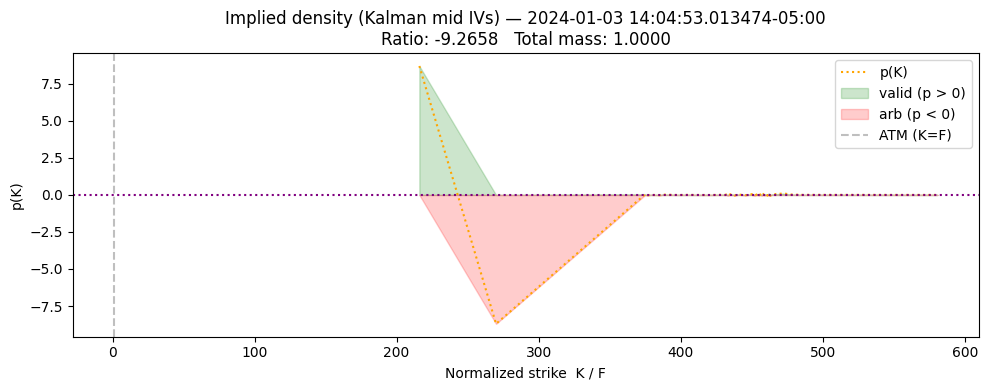

In [47]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title(
    f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
)
ax.set_xlabel("Normalized strike  K / F")
ax.set_ylabel("p(K)")
ax.plot(strikesx, p, ":", color="orange", label="p(K)")
ax.fill_between(strikesx, 0, np.clip(p, 0, None), color="green", alpha=0.2, label="valid (p > 0)")
ax.fill_between(strikesx, np.clip(p, None, 0), 0, color="red", alpha=0.2, label="arb (p < 0)")
ax.axhline(0, color="purple", linestyle=":")
ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
ax.legend()
plt.tight_layout()
plt.show()